# SBERT

In this notebook, the candidates are ranked in terms of their similarity to 2 different target job titles - Aspiring Human Rescources (query 1) and Seeking Human Resources (query 2).

The words are converted to embeddings using an SBERT model.

The similarities of the candidate and target vectors are then assessed using the cosine similarity.

These similarities are compared to the manual scores assigned to the candidates.

The useful data is then saved to a pickle file.

In [1]:
# import necessary libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sentence_transformers import SentenceTransformer
from sklearn.metrics.pairwise import cosine_similarity

In [2]:
# remove limit of column display width so full job titles can be viewed
pd.set_option('display.max_colwidth', None)

In [3]:
# import the cleaned data from CSV file
data = pd.read_csv('../data/potential_talents_cleaned.csv')

In [4]:
# view the first few data rows
data.head()

,id,job_title,location,connection,fit,job_title_stem,manual_score
0,1,2019 c t bauer college of business graduate magna cum laude and aspiring hr professional,"Houston, Texas",85,NaN,2019 c t bauer colleg of busi graduat magna cum laud and aspir hr profession,5
1,2,native english teacher at epik english program in korea,Kanada,500+,NaN,nativ english teacher at epik english program in korea,1
2,3,aspiring hr professional,"Raleigh-Durham, North Carolina Area",44,NaN,aspir hr profession,5
3,4,people development coordinator at ryan,"Denton, Texas",500+,NaN,peopl develop coordin at ryan,3
4,5,advisory board member at celal bayar university,"İzmir, Türkiye",500+,NaN,advisori board member at celal bayar univers,1


In [5]:
# defining sentence transformer model to use
model = SentenceTransformer('all-MiniLM-L6-v2')

# creating embeddings of the target job titles
target_title_q1 = 'aspiring human resources'
target_embedding_q1 = model.encode([target_title_q1])

target_title_q2 = 'seeking human resources'
target_embedding_q2 = model.encode([target_title_q2])

# creating embeddings of the words in the job titles and adding them into the df as a column
job_embeddings = model.encode(data['job_title'].to_list())
data['embeddings'] = list(job_embeddings)

# list different types of similarity scorers
similarity_scorers = ['cosine', 'dot', 'euclidean', 'manhattan']

# using each scorer to assess the similarities
for scorer in similarity_scorers:
    model.similarity_fn_name = scorer
    similarities = model.similarity(target_embedding_q1, job_embeddings).flatten()
    data[f'{scorer}_similarity_q1'] = similarities
    data[f'{scorer}_rank_q1'] = (
        data[f'{scorer}_similarity_q1']
        .rank(ascending=False, method='min')
        .astype(int)
    )

for scorer in similarity_scorers:
    model.similarity_fn_name = scorer
    similarities = model.similarity(target_embedding_q2, job_embeddings).flatten()
    data[f'{scorer}_similarity_q2'] = similarities
    data[f'{scorer}_rank_q2'] = (
        data[f'{scorer}_similarity_q2']
        .rank(ascending=False, method='min')
        .astype(int)
    )

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

In [6]:
# display results for query 1
print('Query 1: Aspiring Human Resources')

data = data.sort_values(by='cosine_rank_q1', ascending=True).reset_index(drop=True)
data[['job_title', 'manual_score', 'cosine_rank_q1', 'dot_rank_q1', 'euclidean_rank_q1', 'manhattan_rank_q1']]

Query 1: Aspiring Human Resources


,job_title,manual_score,cosine_rank_q1,dot_rank_q1,euclidean_rank_q1,manhattan_rank_q1
0,aspiring hr professional,5,1,1,1,1
1,aspiring hr professional,5,1,1,1,1
2,aspiring hr specialist,5,3,3,3,3
3,seeking hr opportunities,5,4,4,4,4
4,student at humber college and aspiring hr generalist,5,5,5,5,6
5,seeking hr position,5,6,6,6,5
6,hr staffing and recruiting professional,4,7,7,7,8
7,hr professional,4,8,8,8,9
8,seeking hr hris and generalist positions,5,9,9,9,7
9,aspiring hr professional an energetic and team focused leader,5,10,10,10,10


In [7]:
# display results for query 2
print('Query 2: Seeking Human Resources')

data = data.sort_values(by='cosine_rank_q2', ascending=True).reset_index(drop=True)
data[['job_title', 'manual_score', 'cosine_rank_q2', 'dot_rank_q2', 'euclidean_rank_q2', 'manhattan_rank_q2']]

Query 2: Seeking Human Resources


,job_title,manual_score,cosine_rank_q2,dot_rank_q2,euclidean_rank_q2,manhattan_rank_q2
0,seeking hr opportunities,5,1,1,1,1
1,seeking human resources opportunities open to travel and relocation,5,2,2,2,2
2,seeking hr position,5,3,3,3,3
3,seeking hr hris and generalist positions,5,4,4,4,4
4,hr staffing and recruiting professional,4,5,5,5,5
5,aspiring hr professional,5,6,6,6,6
6,aspiring hr professional,5,6,6,6,6
7,aspiring hr specialist,5,8,8,8,8
8,hr professional,4,9,9,9,9
9,student at humber college and aspiring hr generalist,5,10,10,10,10


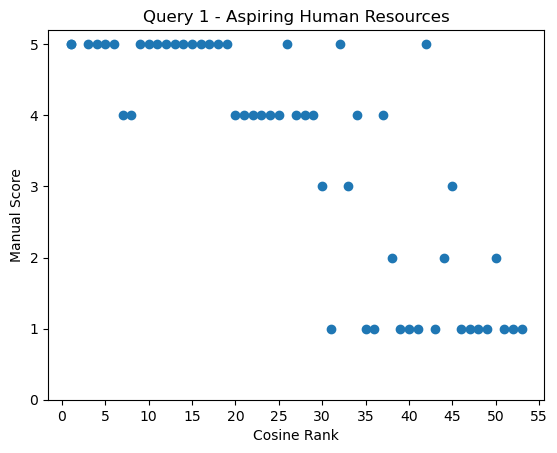

In [6]:
# compare the SBERT rankings to the manual scores for query 1
data = data.sort_values(by='cosine_rank_q1', ascending=True)

x = data['cosine_rank_q1']
y = data['manual_score']

plt.scatter(x, y)
plt.title("Query 1 - Aspiring Human Resources")
plt.xlabel("Cosine Rank")
plt.ylabel("Manual Score")
plt.xticks(np.arange(0, 60, 5))
plt.yticks(np.arange(0, 6))
plt.show()

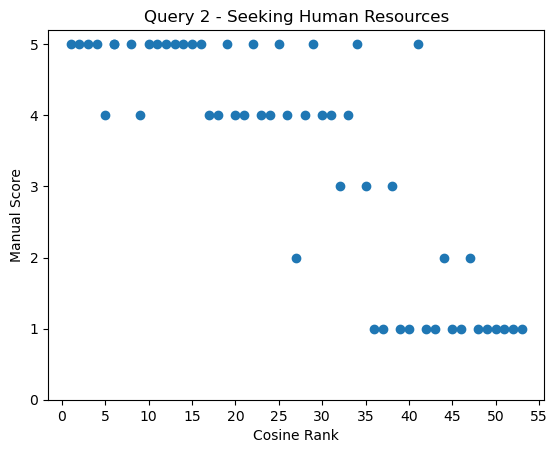

In [7]:
# compare the SBERT rankings to the manual scores for query 2
data = data.sort_values(by='cosine_rank_q2', ascending=True)

x = data['cosine_rank_q2']
y = data['manual_score']

plt.scatter(x, y)
plt.title("Query 2 - Seeking Human Resources")
plt.xlabel("Cosine Rank")
plt.ylabel("Manual Score")
plt.xticks(np.arange(0, 60, 5))
plt.yticks(np.arange(0, 6))
plt.show()

In [9]:
# show all column names the exist in the data
data.columns

Index(['id', 'job_title', 'location', 'connection', 'fit', 'job_title_stem',
       'manual_score', 'embeddings', 'cosine_similarity_q1', 'cosine_rank_q1',
       'dot_similarity_q1', 'dot_rank_q1', 'euclidean_similarity_q1',
       'euclidean_rank_q1', 'manhattan_similarity_q1', 'manhattan_rank_q1',
       'cosine_similarity_q2', 'cosine_rank_q2', 'dot_similarity_q2',
       'dot_rank_q2', 'euclidean_similarity_q2', 'euclidean_rank_q2',
       'manhattan_similarity_q2', 'manhattan_rank_q2'],
      dtype='object')

In [10]:
# extract key columns to be used in other notebooks
data_ranked = data[['id', 'job_title', 'cosine_similarity_q1', 'cosine_rank_q1', 'cosine_similarity_q2', 'cosine_rank_q2', 'embeddings']].reset_index(drop=True)
data_ranked = data_ranked.rename(columns = {
    "cosine_similarity_q1": "sbert_similarity_q1",
    "cosine_similarity_q2": "sbert_similarity_q2",
    "cosine_rank_q1": "sbert_rank_q1",
    "cosine_rank_q2": "sbert_rank_q2"
})

data_ranked

,id,job_title,sbert_similarity_q1,sbert_rank_q1,sbert_similarity_q2,sbert_rank_q2,embeddings
0,28,seeking hr opportunities,0.699635,4,0.746315,1,"[-0.04547423, 0.001320736, -0.0128760375, 0.14145127, 0.054329254, -0.0058560115, -0.0067865252, -0.050916743, -0.03902872, -0.0014819865, -0.029838558, -0.038471397, -0.018151436, 0.026823327, 0.05554014, 0.03573169, 0.0026721705, 0.07057668, 0.08235961, -0.0443126, -0.029467054, 0.018128412, -0.0037288296, -0.13440211, -0.02488654, -0.05375456, 0.0051458073, 0.060437463, -0.019182675, -0.020669341, 0.04505471, 0.0017655774, 0.005359635, 0.019108268, 0.08103758, 0.08475941, -0.009024505, -0.02290725, 0.022777354, 0.008979692, -0.076323695, -0.017983435, -0.03825371, -0.016410785, -0.028011344, -0.037609313, 0.040812053, 0.019316511, 0.010468861, -0.008065055, 0.00942365, -0.039372835, 0.105058186, 0.03924997, -0.005438451, -0.0018725906, -0.025937524, -0.0046366295, -0.009052759, -0.05671717, -0.04316782, -0.01647268, -0.04180265, -0.038545083, -0.015261618, -0.07724067, -0.042455662, 0.11118671, 0.00026760303, -0.08701695, -0.018585805, -0.07897381, -0.10081652, 0.006517242, 0.09459787, -0.011903482, 0.04850504, 0.001861152, 0.087062344, 0.008842434, 0.04571112, -0.051084347, -0.08190061, 0.0952415, -0.0681116, -0.015115059, -0.037773944, 0.03246098, 0.012031355, 0.032235824, 0.035519216, 0.0035312597, -0.05081721, 0.0051270854, 0.038489237, -0.07001196, 0.03859586, 0.14784755, -0.017649928, 0.07430354, ...]"
1,94,seeking human resources opportunities open to travel and relocation,0.564194,17,0.709997,2,"[0.06880151, -0.095295735, 0.012525528, 0.111569814, 0.04137137, 0.016947547, 0.048006278, -0.040225733, -0.0710391, -0.024496632, 0.018827813, -0.01717172, -0.07122937, 0.11455294, 0.008071353, 0.036229197, 0.00032403436, -0.0036628568, 0.05500785, -0.055878665, -0.0050365278, -0.007566781, -0.04323889, -0.08149599, 0.03627062, -0.018642604, 0.036714252, -0.002520063, 0.0409151, 0.034003682, 0.08540676, 0.028266499, -0.062195826, 0.025041651, 0.10167719, 0.1339469, -0.00077783805, -0.03501081, 0.052530684, -0.024952758, 0.020514986, -0.03357547, 0.024234915, -0.02804282, -0.021227032, -0.036515657, 0.038355634, 0.001750749, 0.020326413, 0.025908377, 0.043336924, 0.006039516, 0.062689714, -0.058112163, -0.053645745, -0.009153426, -0.016139515, 0.024548419, -0.029969143, -0.060563695, 0.02375316, 0.022658786, -0.01377895, -0.017727336, -0.018699763, -0.07879589, -0.055896394, 0.088117994, 0.023514468, -0.11562749, -0.015677923, -0.0401062, -0.10195615, 0.018523233, 0.09547034, -0.015710384, 0.027935706, 0.01787672, 0.028283384, 0.013125372, 0.09607789, -0.006393264, -0.09850646, 0.017020065, -0.09728506, -0.007811575, -0.054099847, 0.016361019, 0.027179262, 0.059137113, 0.06010942, -0.06203139, -0.0070498516, 0.011591946, 0.0043885983, -0.047502868, 0.017491635, 0.109021336, 0.012356201, 0.011900557, ...]"
2,99,seeking hr position,0.673482,6,0.693969,3,"[-0.056644112, 0.017239137, -0.023033375, 0.11194457, 0.038311787, 0.022828644, -0.018144183, -0.026748713, -0.052521575, -0.0033154532, -0.054894913, -0.03912208, -0.034104176, -0.023383066, 0.015895007, 0.027486907, 0.009204827, 0.036275145, 0.09723943, -0.05062525, -0.014511232, 0.022784965, 0.03019165, -0.14446561, -0.015167618, -0.026329769, 0.035325814, 0.0642535, -0.039066467, -0.057479817, 0.0137794865, -0.047993775, 0.026865203, 0.023205087, 0.062004574, 0.08322906, -0.023484327, -0.053717665, -0.0050036884, 0.0068392768, -0.04973722, -0.011767695, -0.060105957, -0.045551505, -0.04003109, -0.0118872225, 0.079972126, 0.02673303, 0.013113557, -0.0015389529, -0.017052434, -0.029853662, 0.1019595, 0.04864723, 0.008417552, -0.0018172497, 0.021915559, -0.019523272, -0.039854467, -0.036181875, -0.021087078, -0.032882445, -0.024645897, -0.04604956, 0.007358118, -0.08296183, -0.04645356, 0.050596353, 0.009701574, -0.1167966, -0.010521293, -0.08624135, -0.096323006, 0.0027567032, 0.0749096, -0.027785221, 0.07028806, 0.015264796, 0.097

In [11]:
# save data to pickle file
data_ranked.to_pickle("../data/potential_talents_ranked.pkl")